In [1]:
!pip -q install requests pandas numpy matplotlib scikit-learn tensorflow


In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import pandas as pd
import os

print(os.listdir("/content"))

['.config', 'cat dataset.csv', 'sample_data']


In [8]:
import pandas as pd

file_path = "/content/cat dataset.csv"

# Try loading the CSV with automatic separator detection
df = pd.read_csv(
    file_path,
    sep=None,
    engine="python",
    on_bad_lines="warn"
)

print("Dataset loaded!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Streaming output truncated to the last 5000 lines.

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 14008: Expected 6 fields in line 14008, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 14009: Expected 6 fields in line 14009, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 14010: Expected 6 fields in line 14010, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 14011: Expected 6 fields in line 14011, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 14012: Expected 6 fields in line 14012, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 14013: Expected 6 fields in line 14013, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 14014: Expected 6 fields in line 14014, saw 8

  df = pd.read_csv(
/tmp

Dataset loaded!
Rows: 1
Columns: 6


/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 15674: Expected 6 fields in line 15674, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 15675: Expected 6 fields in line 15675, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 15676: Expected 6 fields in line 15676, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 15677: Expected 6 fields in line 15677, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 15678: Expected 6 fields in line 15678, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 15679: Expected 6 fields in line 15679, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 15680: Expected 6 fields in line 15680, saw 8

  df = pd.read_csv(
/tmp/ipykernel_823/3828882752.py:6: ParserWarning: Skipping line 15681: Expe

,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,13.110721,80.2459,12.0,19800,Asia/Kolkata,GMT+5:30


In [9]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

if len(df) >= 15000:
    print("\n✅ Dataset has 15,000+ rows!")
else:
    print("\n❌ Dataset has less than 15,000 rows.")
    print("Rows needed:", 15000 - len(df))

Dataset Shape: (1, 6)

Column Names:
['latitude', 'longitude', 'elevation', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation']

Missing Values:
latitude                 0
longitude                0
elevation                0
utc_offset_seconds       0
timezone                 0
timezone_abbreviation    0
dtype: int64

Duplicate Rows: 0

❌ Dataset has less than 15,000 rows.
Rows needed: 14999


In [11]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Dataset shape: (1, 6)

Column names:
['latitude', 'longitude', 'elevation', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation']

First 5 rows:


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,13.110721,80.2459,12.0,19800,Asia/Kolkata,GMT+5:30



Data types:
latitude                 float64
longitude                float64
elevation                float64
utc_offset_seconds         int64
timezone                  object
timezone_abbreviation     object
dtype: object


In [12]:
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

Dataset shape: (1, 6)
Column names: ['latitude', 'longitude', 'elevation', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation']


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,13.110721,80.2459,12.0,19800,Asia/Kolkata,GMT+5:30


In [13]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 13.0827,
    "longitude": 80.2707,
    "start_date": "1980-01-01",
    "end_date": "2025-12-31",
    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
        "pressure_msl_mean",
        "precipitation_sum"
    ],
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=120)
print("API status:", response.status_code)
response.raise_for_status()

data = response.json()

if "daily" not in data:
    raise ValueError(data)

df = pd.DataFrame(data["daily"])
df = df.rename(columns={"time": "date"})

print("Weather data loaded!")
print("Dataset shape:", df.shape)
display(df.head())

API status: 200
Weather data loaded!
Dataset shape: (16802, 8)


,date,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,wind_speed_10m_mean,pressure_msl_mean,precipitation_sum
0,1980-01-01,22.8,27.6,17.8,79,7.7,1012.5,0.0
1,1980-01-02,23.4,27.9,19.1,74,7.7,1012.3,0.0
2,1980-01-03,23.4,27.9,18.3,73,6.6,1012.5,0.0
3,1980-01-04,23.7,27.5,18.9,71,10.1,1012.9,0.0
4,1980-01-05,24.6,28.1,21.8,67,12.9,1013.5,0.0


In [14]:
print("Total rows:", len(df))
print("Columns:", df.columns.tolist())

if len(df) >= 15000:
    print("15,000+ records available!")
else:
    print("Rows still needed:", 15000 - len(df))


Total rows: 16802
Columns: ['date', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'wind_speed_10m_mean', 'pressure_msl_mean', 'precipitation_sum']
15,000+ records available!


In [15]:
df["date"] = pd.to_datetime(df["date"])

df = df.drop_duplicates(subset="date")
df = df.sort_values("date").reset_index(drop=True)

features = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "wind_speed_10m_mean",
    "pressure_msl_mean",
    "precipitation_sum"
]

df[features] = df[features].replace([np.inf, -np.inf], np.nan)
df[features] = df[features].interpolate(limit_direction="both")

df = df.dropna(subset=["temperature_2m_mean"]).reset_index(drop=True)

print("Cleaned shape:", df.shape)
print("Missing values:\n", df[features].isnull().sum())
print("Date range:", df["date"].min(), "to", df["date"].max())

Cleaned shape: (16802, 8)
Missing values:
 temperature_2m_mean          0
temperature_2m_max           0
temperature_2m_min           0
relative_humidity_2m_mean    0
wind_speed_10m_mean          0
pressure_msl_mean            0
precipitation_sum            0
dtype: int64
Date range: 1980-01-01 00:00:00 to 2025-12-31 00:00:00


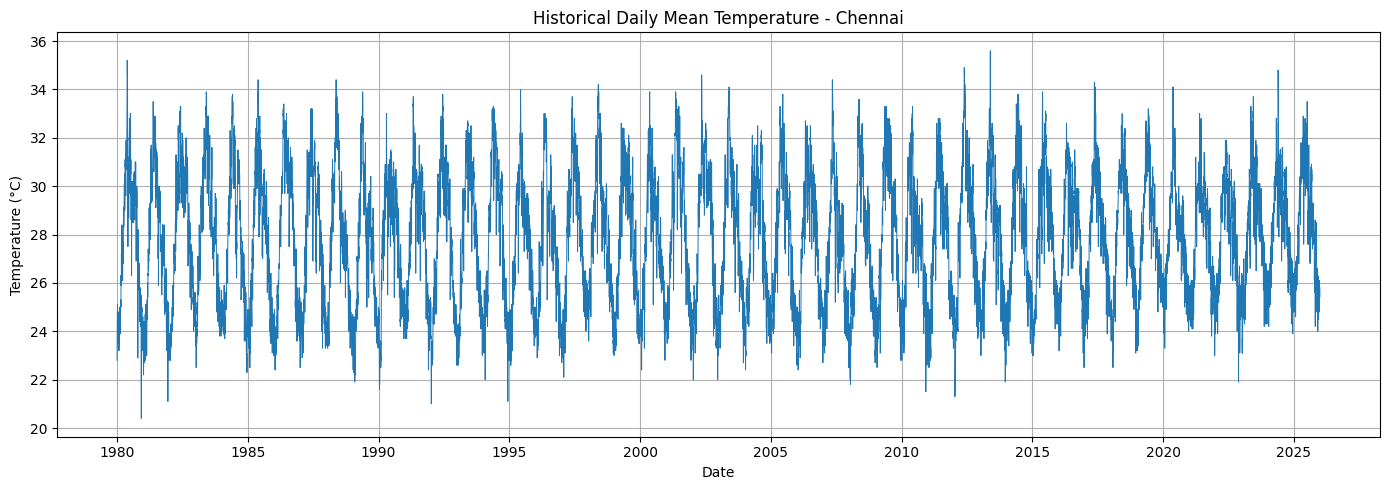

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["temperature_2m_mean"],
    linewidth=0.7
)

plt.title("Historical Daily Mean Temperature - Chennai")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
from sklearn.preprocessing import MinMaxScaler

target = "temperature_2m_mean"
window = 30

split = int(len(df) * 0.80)

scaler = MinMaxScaler()
scaler.fit(df[features].iloc[:split])

scaled = scaler.transform(df[features]).astype("float32")

target_idx = features.index(target)

print("Normalization completed!")
print("Training portion:", split)
print("Testing portion:", len(df) - split)
print("Input features:", len(features))

Normalization completed!
Training portion: 13441
Testing portion: 3361
Input features: 7


In [18]:
X_train, y_train = [], []
X_test, y_test = [], []
test_dates = []

for i in range(window, len(df)):
    x = scaled[i-window:i]
    y = scaled[i, target_idx]

    if i < split:
        X_train.append(x)
        y_train.append(y)
    else:
        X_test.append(x)
        y_test.append(y)
        test_dates.append(df["date"].iloc[i])

X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)

test_dates = pd.to_datetime(test_dates)

print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)
print("Testing inputs:", X_test.shape)
print("Testing targets:", y_test.shape)

Training inputs: (13411, 30, 7)
Training targets: (13411,)
Testing inputs: (3361, 30, 7)
Testing targets: (3361,)


In [19]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

np.random.seed(42)
tf.random.set_seed(42)

model = Sequential([
    Input(shape=(window, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

print("Training completed: 10 epochs!")

Epoch 1/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.0136 - val_loss: 0.0061
Epoch 2/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.0058 - val_loss: 0.0061
Epoch 3/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0048 - val_loss: 0.0062
Epoch 4/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.0041 - val_loss: 0.0047
Epoch 5/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0038 - val_loss: 0.0048
Epoch 6/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.0034 - val_loss: 0.0035
Epoch 7/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.0030 - val_loss: 0.0030
Epoch 8/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - loss: 0.0027 - val_loss: 0.0052
Epoch 9/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.0029 - val_loss: 0.0033
Epoch 10/10
378/378 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0026 - val_loss: 0.0027
Training completed: 10 epochs!


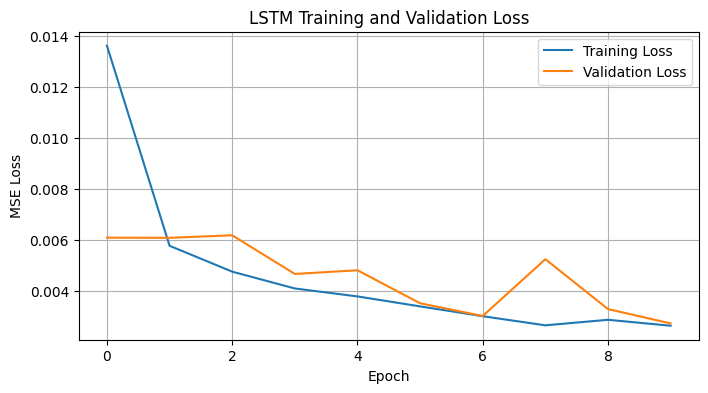

In [21]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

pred_scaled = model.predict(X_test, verbose=0).flatten()

target_min = scaler.data_min_[target_idx]
target_range = scaler.data_range_[target_idx]

pred_temp = pred_scaled * target_range + target_min
actual_temp = y_test * target_range + target_min

mae = mean_absolute_error(actual_temp, pred_temp)
rmse = np.sqrt(mean_squared_error(actual_temp, pred_temp))

print(f"Mean Absolute Error (MAE): {mae:.3f} °C")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f} °C")

Mean Absolute Error (MAE): 0.685 °C
Root Mean Squared Error (RMSE): 0.838 °C


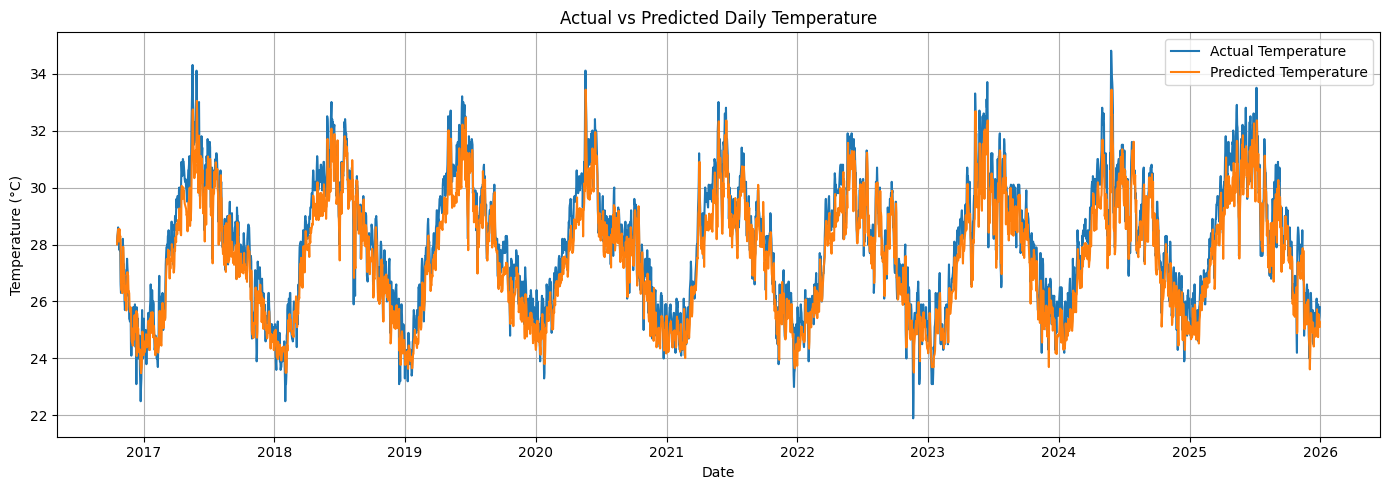

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(test_dates, actual_temp, label="Actual Temperature")
plt.plot(test_dates, pred_temp, label="Predicted Temperature")

plt.title("Actual vs Predicted Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Temperature": actual_temp,
    "Predicted_Temperature": pred_temp
})

results["Absolute_Error"] = np.abs(
    results["Actual_Temperature"] -
    results["Predicted_Temperature"]
)

display(results.head(20))

,Date,Actual_Temperature,Predicted_Temperature,Absolute_Error
0,2016-10-19,28.1,28.005973,0.094026
1,2016-10-20,28.3,28.251117,0.048883
2,2016-10-21,28.4,28.404047,0.004047
3,2016-10-22,28.6,28.525760,0.074240
4,2016-10-23,28.0,28.540347,0.540347
5,2016-10-24,28.1,28.105980,0.005980
6,2016-10-25,27.9,28.461764,0.561764
7,2016-10-26,27.8,28.535916,0.735916
8,2016-10-27,28.1,28.220543,0.120544
9,2016-10-28,27.7,28.301475,0.601475


NameError: name 'forecast' is not defined

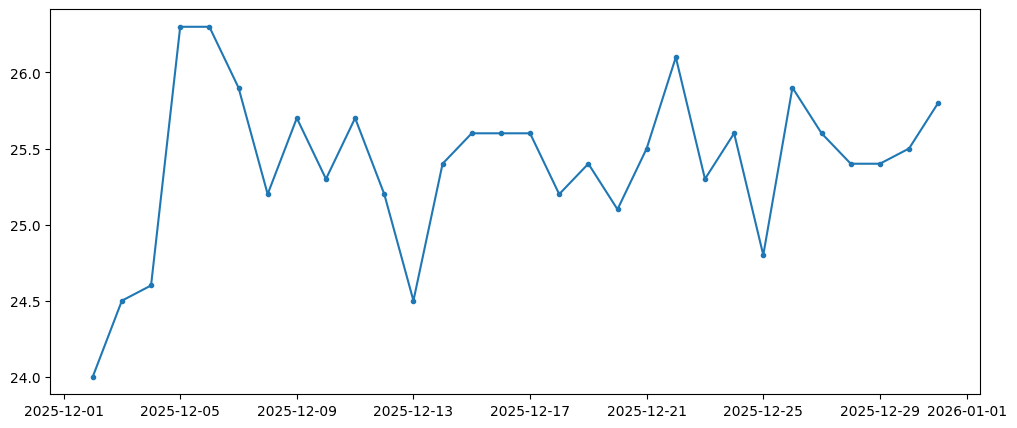

In [25]:
recent = df.tail(30)

plt.figure(figsize=(12, 5))

plt.plot(
    recent["date"],
    recent["temperature_2m_mean"],
    label="Historical Temperature",
    marker="."
)

plt.plot(
    forecast["Date"],
    forecast["Forecast_Temperature_C"],
    label="Forecast Temperature",
    marker="o",
    linestyle="--"
)

plt.title("7-Day Temperature Forecast - Chennai")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [26]:
days = 7
seq = scaled[-window:].copy()
future_scaled = []

for _ in range(days):
    x = seq.reshape(1, window, len(features))
    next_temp = model.predict(x, verbose=0)[0, 0]
    future_scaled.append(next_temp)

    new_row = seq[-1].copy()
    new_row[target_idx] = next_temp
    seq = np.vstack([seq[1:], new_row])

future_temp = np.array(future_scaled) * target_range + target_min

future_dates = pd.date_range(
    start=df["date"].max() + pd.Timedelta(days=1),
    periods=days,
    freq="D"
)

forecast = pd.DataFrame({
    "Date": future_dates,
    "Forecast_Temperature_C": future_temp
})

display(forecast.round(2))

,Date,Forecast_Temperature_C
0,2026-01-01,25.47
1,2026-01-02,25.55
2,2026-01-03,25.63
3,2026-01-04,25.67
4,2026-01-05,25.70
5,2026-01-06,25.73
6,2026-01-07,25.75


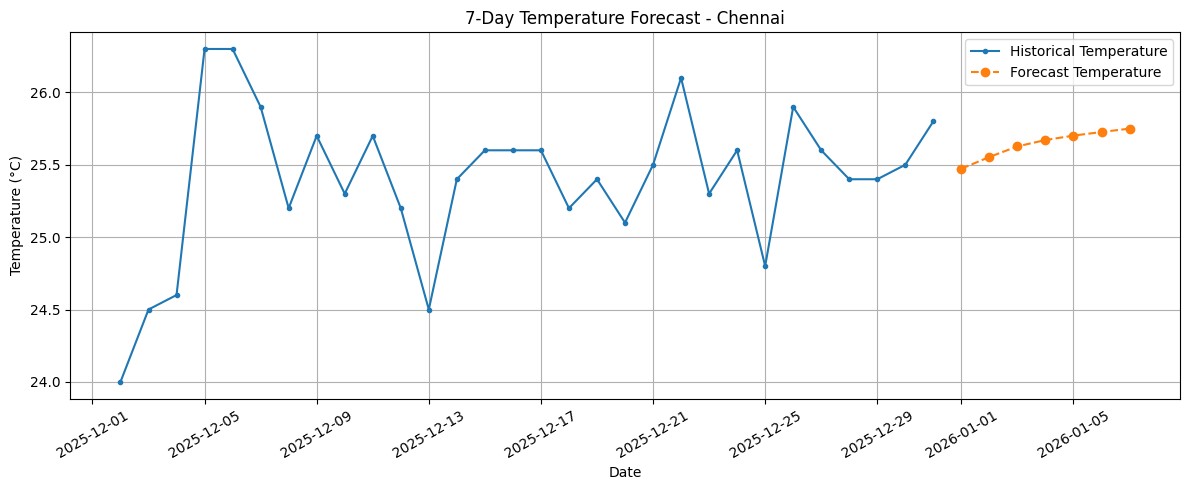

In [27]:
recent = df.tail(30)

plt.figure(figsize=(12, 5))

plt.plot(
    recent["date"],
    recent["temperature_2m_mean"],
    label="Historical Temperature",
    marker="."
)

plt.plot(
    forecast["Date"],
    forecast["Forecast_Temperature_C"],
    label="Forecast Temperature",
    marker="o",
    linestyle="--"
)

plt.title("7-Day Temperature Forecast - Chennai")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [28]:
df.to_csv("cleaned_weather_data.csv", index=False)
results.to_csv("temperature_predictions.csv", index=False)
forecast.to_csv("temperature_forecast.csv", index=False)

from google.colab import files

files.download("cleaned_weather_data.csv")
files.download("temperature_predictions.csv")
files.download("temperature_forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>